In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress
plt.style.use("bmh")

In [2]:
iris_df = pd.read_csv("iris_ascot_runs.csv")
iris_df = iris_df.fillna(0)
iris_df

,job_id,nodes,mpi_tasks_per_node,omp_threads_per_task,runtime
0,600588,1,28.0,1.0,02:52:05
1,600630,2,56.0,1.0,00:43:48
2,600634,2,28.0,2.0,01:27:46
3,600637,2,14.0,4.0,02:38:46
4,600775,4,0.0,0.0,00:22:15
5,600782,4,28.0,0.0,00:44:01
6,600777,4,8.0,0.0,02:17:16
7,604188,4,0.0,0.0,00:22:02


In [3]:
runtimes_dt = pd.to_datetime(iris_df["runtime"], format="%H:%M:%S")
iris_df["runtime_s"] = 3600 * runtimes_dt.dt.hour + 60 * runtimes_dt.dt.minute + runtimes_dt.dt.second
iris_df = iris_df.astype({"mpi_tasks_per_node" : "int64", "omp_threads_per_task" : "int64"})
iris_df

,job_id,nodes,mpi_tasks_per_node,omp_threads_per_task,runtime,runtime_s
0,600588,1,28,1,02:52:05,10325
1,600630,2,56,1,00:43:48,2628
2,600634,2,28,2,01:27:46,5266
3,600637,2,14,4,02:38:46,9526
4,600775,4,0,0,00:22:15,1335
5,600782,4,28,0,00:44:01,2641
6,600777,4,8,0,02:17:16,8236
7,604188,4,0,0,00:22:02,1322


LinregressResult(slope=-1.4826738498432392, intercept=9.128778804657257, rvalue=-0.9821782612414319, pvalue=0.12036972420380303, stderr=0.2837276763944234, intercept_stderr=0.25389347353145936)


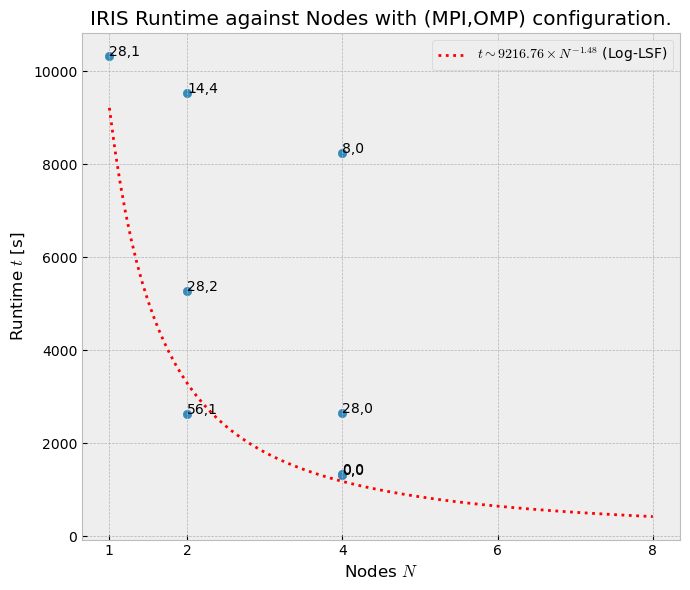

In [14]:
fig, ax = plt.subplots(figsize=(7,6))
ax.scatter(iris_df["nodes"], iris_df["runtime_s"])
for idx, dp in iris_df.iterrows():
    #print(dp)
    ax.annotate(f"{dp['mpi_tasks_per_node']},{dp['omp_threads_per_task']}", xy=(dp["nodes"],dp["runtime_s"]), xycoords="data")
ax.set_xlabel("Nodes $N$")
ax.set_ylabel("Runtime $t$ [s]")
ax.set_title("IRIS Runtime against Nodes with (MPI,OMP) configuration.")
ax.set_xticks([1, 2, 4, 6, 8])

best_runs = iris_df.groupby(by="nodes", as_index=False).agg({"runtime_s" : "min"})
# assume t = a N^b --> ln(t) = ln(a) + b ln(N)
fit = linregress(np.log(best_runs["nodes"]), np.log(best_runs["runtime_s"]))
print(fit)
# ax[1].scatter(np.log(best_runs["nodes"]), np.log(best_runs["runtime_s"]))
# lnn_ends = np.linspace(0, np.log(4), num=100)
# lnt_ends = fit.slope * lnn_ends + fit.intercept
# ax[1].plot(lnn_ends, lnt_ends, c="red", label=f"$R^2$ = {fit.rvalue**2:.3f}")
# ax[1].legend()
n_ends = np.linspace(1, 8, num=100)
ax.plot(n_ends, np.exp(fit.intercept)*np.power(n_ends, fit.slope), c="red", ls=":", label=fr"$t \sim {np.exp(fit.intercept):.2f} \times N^{{{fit.slope:.2f}}}$ (Log-LSF)")
ax.legend()
# ax[1].set_xlabel("Log Nodes $\ln(N)$")
# ax[1].set_ylabel("Log Runtime $\ln(t)$")
# ax[1].set_title("$\ln(t)$ against $\ln(N)$ for Fastest Runs by Node.")

#ax[0].plot(n_ends, np.exp(fit.intercept + fit.slope * n_ends), c="red")

fig.tight_layout()
fig.savefig("IRIS.png")

In [5]:
romeo_df = pd.read_csv("romeo_ascot_runs.csv")
runtimes_dt = pd.to_datetime(romeo_df["runtime"], format="%H:%M:%S")
romeo_df["runtime_s"] = 3600 * runtimes_dt.dt.hour + 60 * runtimes_dt.dt.minute + runtimes_dt.dt.second
romeo_df = romeo_df.astype({"gpus_per_task" : "int64"})
romeo_df

,job_id,nodes,gpus_per_task,runtime,comments,runtime_s
0,510582,4,1,00:07:30,NaN,450
1,510585,4,4,00:07:34,NaN,454
2,510581,2,1,00:12:21,NaN,741
3,510584,2,4,00:12:32,NaN,752
4,510580,1,1,00:23:41,NaN,1421
5,510583,1,4,00:23:44,NaN,1424
6,512241,2,4,00:12:40,NaN,760
7,512246,2,1,00:12:27,NaN,747
8,512243,4,4,00:07:41,NaN,461
9,512240,1,4,00:23:46,NaN,1426


LinregressResult(slope=-0.8294548240128714, intercept=7.2337223847188845, rvalue=-0.9970865528666961, pvalue=0.04860760122741811, stderr=0.06345442203184803, intercept_stderr=0.05678213639687676)


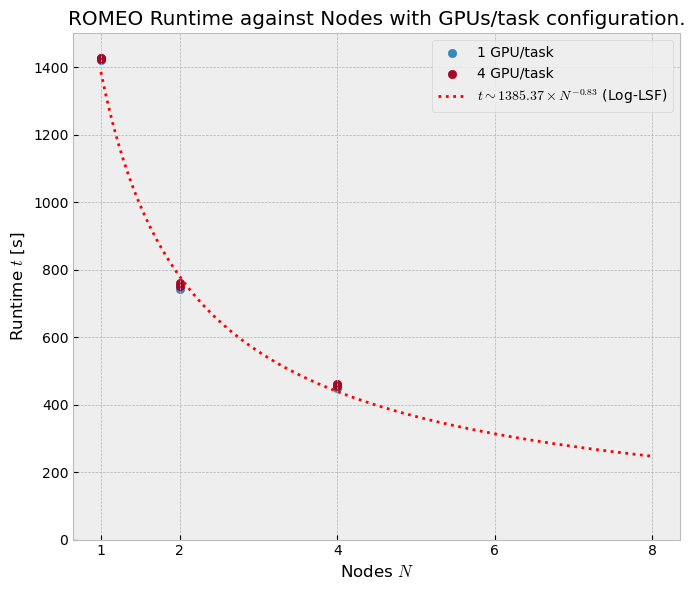

In [11]:
romeo1M_df = romeo_df[romeo_df["comments"] != "5M"]

fig, ax = plt.subplots(figsize=(7,6))
romeo1M_1G_df = romeo1M_df[romeo1M_df["gpus_per_task"] == 1]
romeo1M_4G_df = romeo1M_df[romeo1M_df["gpus_per_task"] == 4]
ax.scatter(romeo1M_1G_df["nodes"], romeo1M_1G_df["runtime_s"], label=f"1 GPU/task")
ax.scatter(romeo1M_4G_df["nodes"], romeo1M_4G_df["runtime_s"], label=f"4 GPU/task")
# for idx, dp in romeo1M_df.iterrows():
#     #print(dp)
#     ax[0].annotate(f"{dp['gpus_per_task']}", xy=(dp["nodes"],dp["runtime_s"]), xycoords="data")
ax.set_xlabel("Nodes $N$")
ax.set_ylabel("Runtime $t$ [s]")
ax.set_title("ROMEO Runtime against Nodes with GPUs/task configuration.")
ax.set_xticks([1, 2, 4, 6, 8])
ax.legend()

best_runs = romeo1M_df.groupby(by="nodes", as_index=False).agg({"runtime_s" : "min"})
# assume t = a N^b --> ln(t) = ln(a) + b ln(N)
fit = linregress(np.log(best_runs["nodes"]), np.log(best_runs["runtime_s"]))
print(fit)
# ax[1].scatter(np.log(best_runs["nodes"]), np.log(best_runs["runtime_s"]))
# lnn_ends = np.linspace(0, np.log(4), num=100)
# lnt_ends = fit.slope * lnn_ends + fit.intercept
# ax[1].plot(lnn_ends, lnt_ends, c="red", label=f"$R^2$ = {fit.rvalue**2:.3f}")
# ax[1].legend()
n_ends = np.linspace(1, 8, num=100)
ax.plot(n_ends, np.exp(fit.intercept)*np.power(n_ends, fit.slope), c="red", ls=":", label=rf"$t \sim {np.exp(fit.intercept):.2f} \times N^{{{fit.slope:.2f}}}$ (Log-LSF)")
ax.legend()
# ax[1].set_xlabel("Log Nodes $\ln(N)$")
# ax[1].set_ylabel("Log Runtime $\ln(t)$")
# ax[1].set_title("$\ln(t)$ against $\ln(N)$ for Fastest Runs by Node.")

#ax[0].plot(n_ends, np.exp(fit.intercept + fit.slope * n_ends), c="red")
ax.set_ylim(0, 1500)
fig.tight_layout()
fig.savefig("ROMEO.png")

[7105, 7105]


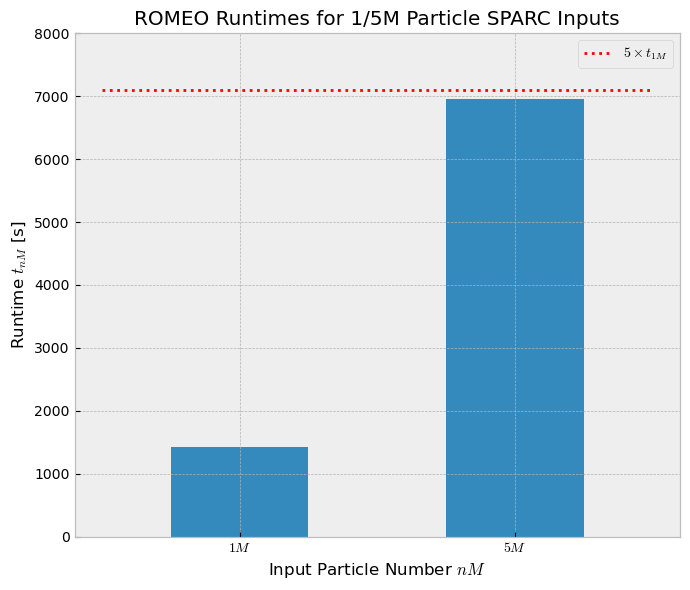

In [7]:
fig, ax = plt.subplots(figsize=(7,6))
ax.bar([r"$1M$", r"$5M$"], romeo_df.loc[[4, 12]]["runtime_s"], width=0.5)
ax.set_xlabel(r"Input Particle Number $nM$")
ax.set_ylabel(r"Runtime $t_{nM}$ [s]")
ax.set_title("ROMEO Runtimes for 1/5M Particle SPARC Inputs")

ax2 = ax.twinx()
x = np.array([-0.5, 1.5])
y = 2*[5 * romeo_df.loc[4]["runtime_s"]]
ax2.plot(x, y, "r:", label=r"$5 \times t_{1M}$")
ax.set_ylim(0, 8000)
ax2.set_ylim(0, 8000)
ax2.get_yaxis().set_visible(False)
ax2.legend()
fig.tight_layout()
fig.savefig("1M5M.png")

In [12]:
5 * romeo_df.loc[4]["runtime_s"] - romeo_df.loc[12]["runtime_s"]

145